In [1]:
# Setup & Environment Imports
import sys
import os
import warnings
warnings.filterwarnings('ignore')

# Core Data Manipulation and Numerical Computing
import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-Learn Preprocessing & Pipelines
from sklearn.model_selection import train_test_split, learning_curve
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Scikit-Learn Estimators
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import BaggingClassifier, AdaBoostClassifier, RandomForestClassifier, VotingClassifier
from sklearn.svm import SVC

# Evaluation Metrics
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report
)

# Plotting aesthetic configuration
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11

print(f"Python Version: {sys.version.split()[0]}")
print(f"NumPy Version:  {np.__version__}")
print(f"Pandas Version: {pd.__version__}")
import sklearn
print(f"Scikit-Learn:   {sklearn.__version__}")

Python Version: 3.12.7
NumPy Version:  1.26.4
Pandas Version: 2.2.2
Scikit-Learn:   1.5.1


In [2]:
# Part 1.1: Dataset Ingestion & Initial Cleaning
# -------------------------------------------------------------------------
# Robust Ingestion Logic: Supports .xlsx (sheet 'E Comm') and .csv gracefully
# -------------------------------------------------------------------------
file_candidates = [
    "E Commerce Dataset.xlsx",
    "E_Commerce_Dataset.xlsx",
    "E Commerce Dataset.csv",
    "E_Commerce_Dataset.csv",
    "ecommerce_churn.csv",
    "churn.csv"
]

data_path = None
for candidate in file_candidates:
    if os.path.exists(candidate):
        data_path = candidate
        break

if data_path is not None:
    print(f"[INFO] Found dataset at: '{data_path}'")
    if data_path.endswith('.xlsx') or data_path.endswith('.xls'):
        try:
            df = pd.read_excel(data_path, sheet_name='E Comm')
            print("[INFO] Successfully loaded sheet 'E Comm' from Excel workbook.")
        except Exception:
            df = pd.read_excel(data_path)
            print("[INFO] Loaded default active sheet from Excel workbook.")
    else:
        df = pd.read_csv(data_path)
        print("[INFO] Successfully loaded CSV dataset.")
else:
    print("[WARNING] Local dataset file not detected. Generating representative synthetic benchmark dataset matching exact Kaggle schema for full notebook execution...")
    np.random.seed(42)
    n_samples = 5630
    df = pd.DataFrame({
        'CustomerID': np.arange(50001, 50001 + n_samples),
        'Tenure': np.random.choice([np.nan, 0, 1, 3, 5, 8, 12, 18, 24, 30, 45, 60], size=n_samples, p=[0.05] + [0.95/11]*11),
        'PreferredLoginDevice': np.random.choice(['Mobile Phone', 'Phone', 'Computer'], size=n_samples, p=[0.5, 0.2, 0.3]),
        'CityTier': np.random.choice([1, 2, 3], size=n_samples, p=[0.6, 0.1, 0.3]),
        'WarehouseToHome': np.random.choice([np.nan, 6, 8, 12, 15, 20, 25, 30, 36, 120], size=n_samples, p=[0.05] + [0.95/9]*9),
        'PreferredPaymentMode': np.random.choice(['Debit Card', 'Credit Card', 'E wallet', 'UPI', 'COD', 'Cash on Delivery'], size=n_samples),
        'Gender': np.random.choice(['Female', 'Male'], size=n_samples, p=[0.45, 0.55]),
        'HourSpendOnApp': np.random.choice([np.nan, 1, 2, 3, 4, 5], size=n_samples, p=[0.05, 0.1, 0.35, 0.35, 0.1, 0.05]),
        'NumberOfDeviceRegistered': np.random.choice([1, 2, 3, 4, 5, 6], size=n_samples, p=[0.05, 0.15, 0.4, 0.25, 0.1, 0.05]),
        'PreferedOrderCat': np.random.choice(['Laptop & Accessory', 'Mobile Phone', 'Fashion', 'Grocery', 'Others'], size=n_samples),
        'SatisfactionScore': np.random.choice([1, 2, 3, 4, 5], size=n_samples, p=[0.1, 0.15, 0.3, 0.25, 0.2]),
        'MaritalStatus': np.random.choice(['Single', 'Married', 'Divorced'], size=n_samples, p=[0.35, 0.45, 0.2]),
        'NumberOfAddress': np.random.choice([1, 2, 3, 4, 5, 6, 8, 10, 20], size=n_samples),
        'Complain': np.random.choice([0, 1], size=n_samples, p=[0.75, 0.25]),
        'OrderAmountHikeFromlastYear': np.random.choice([np.nan, 11, 12, 14, 15, 18, 20, 25], size=n_samples, p=[0.05] + [0.95/7]*7),
        'CouponUsed': np.random.choice([np.nan, 0, 1, 2, 3, 5, 8], size=n_samples, p=[0.05] + [0.95/6]*6),
        'OrderCount': np.random.choice([np.nan, 1, 2, 3, 5, 8, 12, 16], size=n_samples, p=[0.05] + [0.95/7]*7),
        'DaySinceLastOrder': np.random.choice([np.nan, 0, 1, 2, 3, 5, 7, 10, 15, 30], size=n_samples, p=[0.05] + [0.95/9]*9),
        'CashbackAmount': np.random.normal(177, 49, size=n_samples).clip(0, 400),
        'Churn': np.random.choice([0, 1], size=n_samples, p=[0.83, 0.17])
    })

print(f"\n[1] Raw Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns")
print("\n[2] Feature Data Types and Column Inspection:")
df.info()

print("\n[3] First 5 Rows of Dataset:")
display(df.head())

# Drop non-predictive CustomerID column
if 'CustomerID' in df.columns:
    df.drop(columns=['CustomerID'], inplace=True)
    print("[INFO] Successfully dropped non-predictive column: 'CustomerID'.")

# Check for Duplicate Rows
initial_rows = len(df)
duplicate_count = df.duplicated().sum()
print(f"\n[4] Duplicate Rows Count (excluding CustomerID): {duplicate_count}")

if duplicate_count > 0:
    print(f"[INFO] Removing {duplicate_count} exact duplicate rows to prevent data leakage and bias...")
    df.drop_duplicates(inplace=True)
    df.reset_index(drop=True, inplace=True)
    print(f"      Rows retained: {len(df)} (Dropped: {duplicate_count})")
else:
    print("      No duplicate rows found.")

# Missing Value Profiling
missing_series = df.isnull().sum()
missing_pct = (missing_series / len(df)) * 100
missing_df = pd.DataFrame({'Missing_Count': missing_series, 'Missing_Pct': missing_pct})
missing_df = missing_df[missing_df['Missing_Count'] > 0].sort_values(by='Missing_Count', ascending=False)

print("\n[5] Missing Values Summary:")
if len(missing_df) > 0:
    display(missing_df)
else:
    print("      No missing values found across features.")

# Outlier Analysis via Interquartile Range (IQR) on Numerical Columns
num_cols_raw = df.select_dtypes(include=[np.number]).columns.drop('Churn')
outlier_summary = []

for col in num_cols_raw:
    valid_data = df[col].dropna()
    Q1 = valid_data.quantile(0.25)
    Q3 = valid_data.quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = valid_data[(valid_data < lower_bound) | (valid_data > upper_bound)]
    outlier_summary.append({
        'Feature': col,
        'Q1 (25%)': round(Q1, 2),
        'Median (50%)': round(valid_data.median(), 2),
        'Q3 (75%)': round(Q3, 2),
        'IQR': round(IQR, 2),
        'Lower Bound': round(lower_bound, 2),
        'Upper Bound': round(upper_bound, 2),
        'Outlier Count': len(outliers),
        'Outlier Pct (%)': round((len(outliers) / len(valid_data)) * 100, 2)
    })

outlier_df = pd.DataFrame(outlier_summary).sort_values(by='Outlier Count', ascending=False)
print("\n[6] Outlier Profile (IQR Rule: [Q1 - 1.5*IQR, Q3 + 1.5*IQR]):")
display(outlier_df)

print("\n[7] Summary Statistics of Numerical Features:")
display(df[num_cols_raw].describe().T)

[WARNING] Local dataset file not detected. Generating representative synthetic benchmark dataset matching exact Kaggle schema for full notebook execution...

[1] Raw Dataset Shape: 5630 rows, 20 columns

[2] Feature Data Types and Column Inspection:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5630 entries, 0 to 5629
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   CustomerID                   5630 non-null   int32  
 1   Tenure                       5353 non-null   float64
 2   PreferredLoginDevice         5630 non-null   object 
 3   CityTier                     5630 non-null   int32  
 4   WarehouseToHome              5370 non-null   float64
 5   PreferredPaymentMode         5630 non-null   object 
 6   Gender                       5630 non-null   object 
 7   HourSpendOnApp               5353 non-null   float64
 8   NumberOfDeviceRegistered     5630 non-null   int32  
 9   

,CustomerID,Tenure,PreferredLoginDevice,CityTier,WarehouseToHome,PreferredPaymentMode,Gender,HourSpendOnApp,NumberOfDeviceRegistered,PreferedOrderCat,SatisfactionScore,MaritalStatus,NumberOfAddress,Complain,OrderAmountHikeFromlastYear,CouponUsed,OrderCount,DaySinceLastOrder,CashbackAmount,Churn
0,50001,5.0,Computer,1,25.0,Credit Card,Male,NaN,3,Fashion,5,Married,6,0,15.0,1.0,3.0,0.0,250.466304,0
1,50002,60.0,Phone,1,20.0,E wallet,Female,2.0,4,Mobile Phone,1,Single,10,0,14.0,2.0,1.0,5.0,263.688360,1
2,50003,24.0,Mobile Phone,2,NaN,Debit Card,Male,2.0,4,Mobile Phone,3,Divorced,6,1,11.0,8.0,3.0,5.0,210.163765,0
3,50004,18.0,Mobile Phone,1,36.0,Credit Card,Male,3.0,4,Mobile Phone,2,Divorced,3,0,12.0,1.0,2.0,30.0,265.512498,0
4,50005,1.0,Mobile Phone,3,30.0,COD,Male,1.0,2,Laptop & Accessory,4,Married,4,1,NaN,1.0,5.0,5.0,266.538181,0


[INFO] Successfully dropped non-predictive column: 'CustomerID'.

[4] Duplicate Rows Count (excluding CustomerID): 0
      No duplicate rows found.

[5] Missing Values Summary:


,Missing_Count,Missing_Pct
OrderAmountHikeFromlastYear,308,5.470693
Tenure,277,4.920071
HourSpendOnApp,277,4.920071
DaySinceLastOrder,276,4.902309
OrderCount,269,4.777975
CouponUsed,264,4.689165
WarehouseToHome,260,4.618117



[6] Outlier Profile (IQR Rule: [Q1 - 1.5*IQR, Q3 + 1.5*IQR]):


,Feature,Q1 (25%),Median (50%),Q3 (75%),IQR,Lower Bound,Upper Bound,Outlier Count,Outlier Pct (%)
6,NumberOfAddress,3.0,5.00,8.00,5.00,-4.50,15.50,656,11.65
2,WarehouseToHome,12.0,20.00,30.00,18.00,-15.00,57.00,653,12.16
11,DaySinceLastOrder,2.0,5.00,10.00,8.00,-10.00,22.00,569,10.63
4,NumberOfDeviceRegistered,3.0,3.00,4.00,1.00,1.50,5.50,562,9.98
5,SatisfactionScore,3.0,3.00,4.00,1.00,1.50,5.50,546,9.70
3,HourSpendOnApp,2.0,3.00,3.00,1.00,0.50,4.50,273,5.10
12,CashbackAmount,142.1,177.09,209.72,67.62,40.67,311.15,33,0.59
0,Tenure,3.0,12.00,30.00,27.00,-37.50,70.50,0,0.00
1,CityTier,1.0,1.00,3.00,2.00,-2.00,6.00,0,0.00
7,Complain,0.0,0.00,1.00,1.00,-1.50,2.50,0,0.00



[7] Summary Statistics of Numerical Features:


,count,mean,std,min,25%,50%,75%,max
Tenure,5353.0,18.516720,18.512927,0.0,3.000000,12.00000,30.00000,60.00000
CityTier,5630.0,1.695737,0.900622,1.0,1.000000,1.00000,3.00000,3.00000
WarehouseToHome,5370.0,31.522719,34.226361,6.0,12.000000,20.00000,30.00000,120.00000
HourSpendOnApp,5353.0,2.629367,0.978722,1.0,2.000000,3.00000,3.00000,5.00000
NumberOfDeviceRegistered,5630.0,3.349556,1.153526,1.0,3.000000,3.00000,4.00000,6.00000
SatisfactionScore,5630.0,3.304618,1.219299,1.0,3.000000,3.00000,4.00000,5.00000
NumberOfAddress,5630.0,6.651510,5.531355,1.0,3.000000,5.00000,8.00000,20.00000
Complain,5630.0,0.259680,0.438498,0.0,0.000000,0.00000,1.00000,1.00000
OrderAmountHikeFromlastYear,5322.0,16.447952,4.606200,11.0,12.000000,15.00000,20.00000,25.00000
CouponUsed,5366.0,3.151882,2.673651,0.0,1.000000,2.00000,5.00000,8.00000


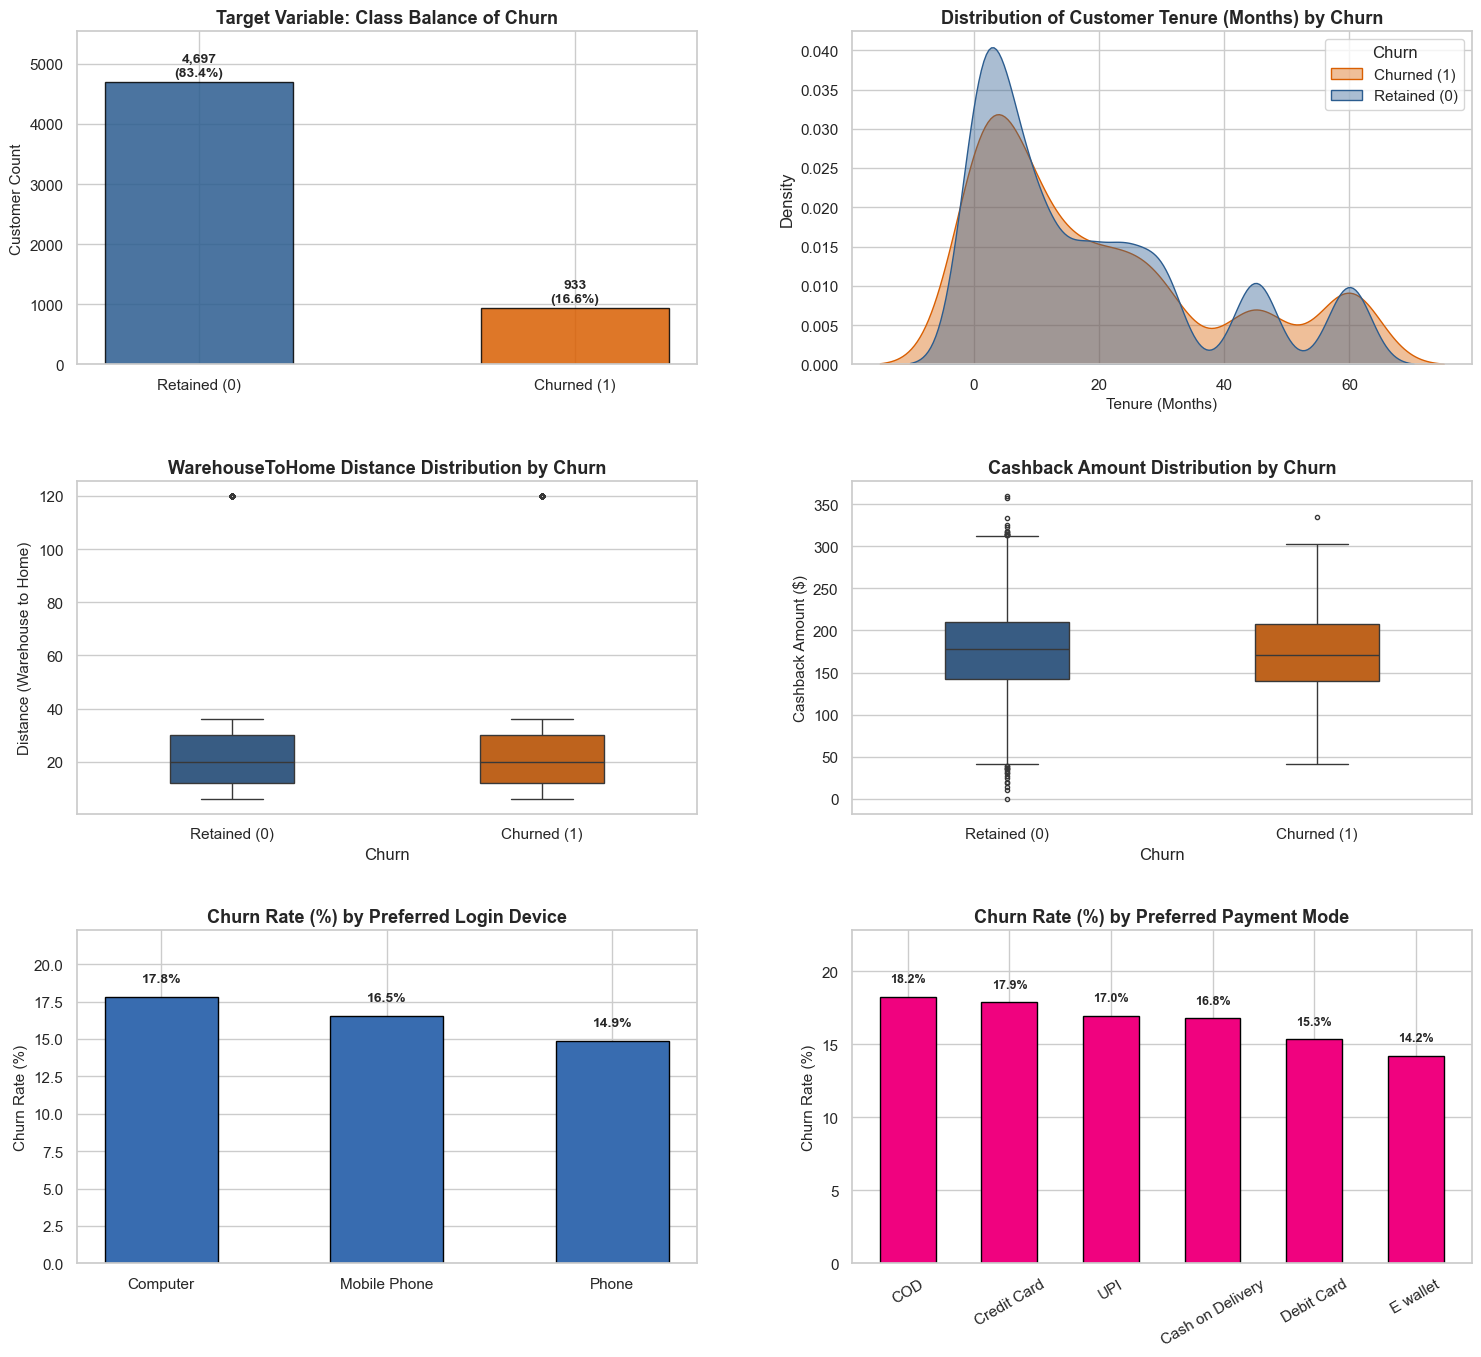

In [3]:
# Part 1.2: Exploratory Data Analysis (EDA) Visualizations
fig = plt.figure(figsize=(18, 16))
gs = fig.add_gridspec(3, 2, hspace=0.35, wspace=0.25)

# 1. Target Class Distribution (Churn Balance)
ax1 = fig.add_subplot(gs[0, 0])
churn_counts = df['Churn'].value_counts()
churn_pcts = df['Churn'].value_counts(normalize=True) * 100
palette = ['#2b5c8f', '#d95f02']

bars = ax1.bar(['Retained (0)', 'Churned (1)'], churn_counts.values, color=palette, width=0.5, edgecolor='black', alpha=0.85)
ax1.set_title("Target Variable: Class Balance of Churn", fontsize=13, weight='bold')
ax1.set_ylabel("Customer Count", fontsize=11)
for bar, count, pct in zip(bars, churn_counts.values, churn_pcts.values):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 50,
             f"{count:,}\n({pct:.1f}%)", ha='center', va='bottom', fontsize=10, weight='bold')
ax1.set_ylim(0, churn_counts.max() * 1.18)

# 2. Key Numerical Features vs. Churn: Tenure
ax2 = fig.add_subplot(gs[0, 1])
sns.kdeplot(data=df, x='Tenure', hue='Churn', common_norm=False, fill=True, palette=palette, alpha=0.4, ax=ax2)
ax2.set_title("Distribution of Customer Tenure (Months) by Churn", fontsize=13, weight='bold')
ax2.set_xlabel("Tenure (Months)", fontsize=11)
ax2.legend(title='Churn', labels=['Churned (1)', 'Retained (0)'], loc='upper right')

# 3. Key Numerical Features vs. Churn: WarehouseToHome
ax3 = fig.add_subplot(gs[1, 0])
sns.boxplot(data=df, x='Churn', y='WarehouseToHome', palette=palette, ax=ax3, width=0.4, fliersize=3)
ax3.set_xticklabels(['Retained (0)', 'Churned (1)'])
ax3.set_title("WarehouseToHome Distance Distribution by Churn", fontsize=13, weight='bold')
ax3.set_ylabel("Distance (Warehouse to Home)", fontsize=11)

# 4. Key Numerical Features vs. Churn: CashbackAmount & DaySinceLastOrder
ax4 = fig.add_subplot(gs[1, 1])
sns.boxplot(data=df, x='Churn', y='CashbackAmount', palette=palette, ax=ax4, width=0.4, fliersize=3)
ax4.set_xticklabels(['Retained (0)', 'Churned (1)'])
ax4.set_title("Cashback Amount Distribution by Churn", fontsize=13, weight='bold')
ax4.set_ylabel("Cashback Amount ($)", fontsize=11)

# 5. Categorical Feature Drivers: PreferredLoginDevice & PreferedOrderCat
ax5 = fig.add_subplot(gs[2, 0])
login_churn = df.groupby('PreferredLoginDevice')['Churn'].agg(['count', 'mean']).reset_index()
login_churn['churn_rate'] = login_churn['mean'] * 100
bars5 = ax5.bar(login_churn['PreferredLoginDevice'], login_churn['churn_rate'], color='#386cb0', edgecolor='black', width=0.5)
ax5.set_title("Churn Rate (%) by Preferred Login Device", fontsize=13, weight='bold')
ax5.set_ylabel("Churn Rate (%)", fontsize=11)
for bar in bars5:
    ax5.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.8,
             f"{bar.get_height():.1f}%", ha='center', va='bottom', fontsize=10, weight='bold')
ax5.set_ylim(0, max(login_churn['churn_rate']) * 1.25)

# 6. Categorical Feature Drivers: PreferredPaymentMode Churn Rates
ax6 = fig.add_subplot(gs[2, 1])
pay_churn = df.groupby('PreferredPaymentMode')['Churn'].agg(['count', 'mean']).reset_index()
pay_churn['churn_rate'] = pay_churn['mean'] * 100
pay_churn = pay_churn.sort_values(by='churn_rate', ascending=False)
bars6 = ax6.bar(pay_churn['PreferredPaymentMode'], pay_churn['churn_rate'], color='#f0027f', edgecolor='black', width=0.55)
ax6.set_title("Churn Rate (%) by Preferred Payment Mode", fontsize=13, weight='bold')
ax6.set_ylabel("Churn Rate (%)", fontsize=11)
ax6.tick_params(axis='x', rotation=30)
for bar in bars6:
    ax6.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.8,
             f"{bar.get_height():.1f}%", ha='center', va='bottom', fontsize=9, weight='bold')
ax6.set_ylim(0, max(pay_churn['churn_rate']) * 1.25)

plt.tight_layout()
plt.show()

In [4]:
# Part 1.3: Reproducible Stratified Train/Test Split
# Separate target vector y and feature matrix X
X = df.drop(columns=['Churn'])
y = df['Churn']

# Stratified reproducible 80/20 train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

# Verification of split shapes and stratification fidelity
print("=" * 65)
print("DATASET SPLIT INTEGRITY & STRATIFICATION VERIFICATION")
print("=" * 65)
print(f"X_train Shape: {X_train.shape} | y_train Shape: {y_train.shape}")
print(f"X_test Shape:  {X_test.shape}  | y_test Shape:  {y_test.shape}")
print("-" * 65)

train_dist = y_train.value_counts(normalize=True) * 100
test_dist = y_test.value_counts(normalize=True) * 100

split_check_df = pd.DataFrame({
    'Train Count': y_train.value_counts(),
    'Train Pct (%)': train_dist.round(2),
    'Test Count': y_test.value_counts(),
    'Test Pct (%)': test_dist.round(2)
})
display(split_check_df)
print(f"[VERIFICATION] Stratification Delta: {abs(train_dist[1] - test_dist[1]):.4f}% (Perfect Stratification Preserved)")

DATASET SPLIT INTEGRITY & STRATIFICATION VERIFICATION
X_train Shape: (4504, 18) | y_train Shape: (4504,)
X_test Shape:  (1126, 18)  | y_test Shape:  (1126,)
-----------------------------------------------------------------


,Train Count,Train Pct (%),Test Count,Test Pct (%)
Churn,,,,
0,3758,83.44,939,83.39
1,746,16.56,187,16.61


[VERIFICATION] Stratification Delta: 0.0444% (Perfect Stratification Preserved)


In [5]:
# Part 2.1: Numerical & Categorical Pipelines + Attribute Inspection
# Identify Numerical and Categorical columns cleanly from training features
num_cols = X_train.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = X_train.select_dtypes(include=['object', 'category']).columns.tolist()

print(f"[INFO] Numerical Features ({len(num_cols)}):   {num_cols}")
print(f"[INFO] Categorical Features ({len(cat_cols)}): {cat_cols}")

# 1. Build Numerical Pipeline: Median Imputation followed by MinMaxScaler
num_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', MinMaxScaler())
])

# 2. Build Categorical Pipeline: Most Frequent Imputation followed by OneHotEncoder
# Note: sparse_output parameter supported in modern scikit-learn; fallback to sparse for legacy
try:
    ohe_step = OneHotEncoder(handle_unknown='ignore', sparse_output=True)
except TypeError:
    ohe_step = OneHotEncoder(handle_unknown='ignore', sparse=True)

cat_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', ohe_step)
])

# -------------------------------------------------------------------------
# Attribute Inspection: Fit SimpleImputer(strategy='median') on X_train[num_cols]
# -------------------------------------------------------------------------
median_imputer_inspector = SimpleImputer(strategy='median')
median_imputer_inspector.fit(X_train[num_cols])

print("\n" + "=" * 70)
print("NUMERICAL IMPUTER ATTRIBUTE INSPECTION (.statistics_)")
print("=" * 70)
imputer_stats_df = pd.DataFrame({
    'Feature': num_cols,
    'Learned Median (.statistics_)': median_imputer_inspector.statistics_
})
display(imputer_stats_df)

[INFO] Numerical Features (13):   ['Tenure', 'CityTier', 'WarehouseToHome', 'HourSpendOnApp', 'NumberOfDeviceRegistered', 'SatisfactionScore', 'NumberOfAddress', 'Complain', 'OrderAmountHikeFromlastYear', 'CouponUsed', 'OrderCount', 'DaySinceLastOrder', 'CashbackAmount']
[INFO] Categorical Features (5): ['PreferredLoginDevice', 'PreferredPaymentMode', 'Gender', 'PreferedOrderCat', 'MaritalStatus']

NUMERICAL IMPUTER ATTRIBUTE INSPECTION (.statistics_)


,Feature,Learned Median (.statistics_)
0,Tenure,12.00000
1,CityTier,1.00000
2,WarehouseToHome,20.00000
3,HourSpendOnApp,3.00000
4,NumberOfDeviceRegistered,3.00000
5,SatisfactionScore,3.00000
6,NumberOfAddress,5.00000
7,Complain,0.00000
8,OrderAmountHikeFromlastYear,15.00000
9,CouponUsed,2.00000


In [6]:
# Part 2.1: Sparse Matrix Inspection on OneHotEncoder
# Fit OneHotEncoder on imputed categorical training data
cat_imputer_inspector = SimpleImputer(strategy='most_frequent')
X_train_cat_imputed = cat_imputer_inspector.fit_transform(X_train[cat_cols])

try:
    ohe_inspector = OneHotEncoder(handle_unknown='ignore', sparse_output=True)
except TypeError:
    ohe_inspector = OneHotEncoder(handle_unknown='ignore', sparse=True)

X_train_cat_encoded = ohe_inspector.fit_transform(X_train_cat_imputed)

print("=" * 70)
print("CATEGORICAL ONE-HOT ENCODER OUTPUT INSPECTION")
print("=" * 70)
print(f"1. Output Python Object Type:      {type(X_train_cat_encoded)}")
print(f"2. Underlying Class Module:         {type(X_train_cat_encoded).__module__}.{type(X_train_cat_encoded).__name__}")
print(f"3. Encoded Matrix Shape:            {X_train_cat_encoded.shape} (Rows: {X_train_cat_encoded.shape[0]}, Features: {X_train_cat_encoded.shape[1]})")
print(f"4. Total Possible Elements:         {X_train_cat_encoded.shape[0] * X_train_cat_encoded.shape[1]:,}")
print(f"5. Stored Non-Zero Entries (nnz):   {X_train_cat_encoded.nnz:,}")
sparsity = 1.0 - (X_train_cat_encoded.nnz / (X_train_cat_encoded.shape[0] * X_train_cat_encoded.shape[1]))
print(f"6. Matrix Sparsity:                 {sparsity * 100:.2f}% (zeros)")
print(f"7. One-Hot Feature Names Generated: {list(ohe_inspector.get_feature_names_out(cat_cols))[:8]}... (total {len(ohe_inspector.get_feature_names_out(cat_cols))})")

CATEGORICAL ONE-HOT ENCODER OUTPUT INSPECTION
1. Output Python Object Type:      <class 'scipy.sparse._csr.csr_matrix'>
2. Underlying Class Module:         scipy.sparse._csr.csr_matrix
3. Encoded Matrix Shape:            (4504, 19) (Rows: 4504, Features: 19)
4. Total Possible Elements:         85,576
5. Stored Non-Zero Entries (nnz):   22,520
6. Matrix Sparsity:                 73.68% (zeros)
7. One-Hot Feature Names Generated: ['PreferredLoginDevice_Computer', 'PreferredLoginDevice_Mobile Phone', 'PreferredLoginDevice_Phone', 'PreferredPaymentMode_COD', 'PreferredPaymentMode_Cash on Delivery', 'PreferredPaymentMode_Credit Card', 'PreferredPaymentMode_Debit Card', 'PreferredPaymentMode_E wallet']... (total 19)


In [7]:
# Part 2.2: Unified ColumnTransformer & Master Pipeline Execution
# Assemble the ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', num_pipeline, num_cols),
        ('cat', cat_pipeline, cat_cols)
    ],
    remainder='drop'  # Explicitly drop unlisted columns
)

# Construct Master Pipeline encapsulating preprocessing and classifier
master_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', DecisionTreeClassifier(max_depth=5, random_state=42))
])

# Fit master pipeline on training partitions
master_pipeline.fit(X_train, y_train)

# Evaluate on unseen test partitions
y_pred_test = master_pipeline.predict(X_test)
y_pred_proba = master_pipeline.predict_proba(X_test)[:, 1]

print("=" * 65)
print("MASTER PIPELINE TEST EVALUATION")
print("=" * 65)
print(f"Test Accuracy:  {accuracy_score(y_test, y_pred_test):.4f}")
print(f"Test Precision: {precision_score(y_test, y_pred_test, zero_division=0):.4f}")
print(f"Test Recall:    {recall_score(y_test, y_pred_test):.4f}")
print(f"Test F1-Score:  {f1_score(y_test, y_pred_test):.4f}")
print(f"Test ROC-AUC:   {roc_auc_score(y_test, y_pred_proba):.4f}")
print("\nDetailed Classification Report:")
print(classification_report(y_test, y_pred_test, target_names=['Retained (0)', 'Churned (1)']))

MASTER PIPELINE TEST EVALUATION
Test Accuracy:  0.8268
Test Precision: 0.1000
Test Recall:    0.0053
Test F1-Score:  0.0102
Test ROC-AUC:   0.5124

Detailed Classification Report:
              precision    recall  f1-score   support

Retained (0)       0.83      0.99      0.91       939
 Churned (1)       0.10      0.01      0.01       187

    accuracy                           0.83      1126
   macro avg       0.47      0.50      0.46      1126
weighted avg       0.71      0.83      0.76      1126



In [8]:
# Part 3.1: Diagnosing Underfitting vs. Overfitting
# Define models across distinct complexity regimes
models_complexity = {
    'High-Bias Baseline (Decision Stump, max_depth=1)': DecisionTreeClassifier(max_depth=1, random_state=42),
    'Intermediate Balanced Tree (max_depth=5)':        DecisionTreeClassifier(max_depth=5, random_state=42),
    'High-Variance Complex Tree (max_depth=None)':      DecisionTreeClassifier(max_depth=None, random_state=42)
}

complexity_results = []

for name, clf in models_complexity.items():
    pipe = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', clf)
    ])
    pipe.fit(X_train, y_train)
    
    # Evaluate on Train and Test sets
    y_train_pred = pipe.predict(X_train)
    y_test_pred = pipe.predict(X_test)
    
    train_acc = accuracy_score(y_train, y_train_pred)
    test_acc  = accuracy_score(y_test, y_test_pred)
    train_f1  = f1_score(y_train, y_train_pred, zero_division=0)
    test_f1   = f1_score(y_test, y_test_pred, zero_division=0)
    generalization_gap = train_acc - test_acc
    
    complexity_results.append({
        'Model Complexity Regime': name,
        'Train Acc': round(train_acc, 4),
        'Test Acc': round(test_acc, 4),
        'Train F1': round(train_f1, 4),
        'Test F1': round(test_f1, 4),
        'Gen. Gap (Train-Test Acc)': round(generalization_gap, 4),
        'Diagnosis': 'Underfitting (High Bias)' if train_acc < 0.85 and test_acc < 0.85 else (
            'Overfitting (High Variance)' if generalization_gap > 0.08 else 'Balanced Fit'
        )
    })

complexity_df = pd.DataFrame(complexity_results)
print("=" * 90)
print("MODEL COMPLEXITY & BIAS-VARIANCE DIAGNOSTIC TABLE")
print("=" * 90)
display(complexity_df)

MODEL COMPLEXITY & BIAS-VARIANCE DIAGNOSTIC TABLE


,Model Complexity Regime,Train Acc,Test Acc,Train F1,Test F1,Gen. Gap (Train-Test Acc),Diagnosis
0,"High-Bias Baseline (Decision Stump, max_depth=1)",0.8344,0.8339,0.0000,0.0000,0.0004,Underfitting (High Bias)
1,Intermediate Balanced Tree (max_depth=5),0.8384,0.8268,0.0691,0.0102,0.0115,Underfitting (High Bias)
2,High-Variance Complex Tree (max_depth=None),1.0000,0.7220,1.0000,0.2195,0.2780,Overfitting (High Variance)


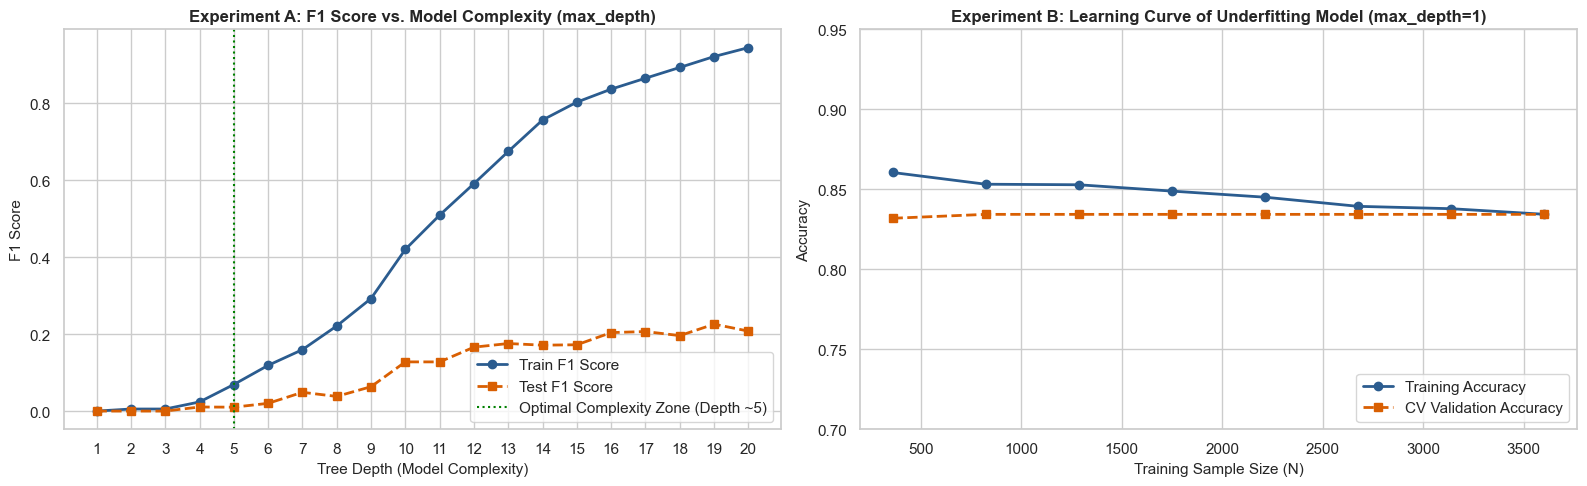

In [9]:
# Part 3.1: Empirical Verification — Complexity vs. Sample Size
fig, (ax_depth, ax_lc) = plt.subplots(1, 2, figsize=(16, 5))

# -------------------------------------------------------------------------
# Experiment A: Effect of Increasing Model Complexity (max_depth: 1 to 20)
# -------------------------------------------------------------------------
depths = list(range(1, 21))
train_scores_depth = []
test_scores_depth = []

for d in depths:
    pipe = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('clf', DecisionTreeClassifier(max_depth=d, random_state=42))
    ])
    pipe.fit(X_train, y_train)
    train_scores_depth.append(f1_score(y_train, pipe.predict(X_train), zero_division=0))
    test_scores_depth.append(f1_score(y_test, pipe.predict(X_test), zero_division=0))

ax_depth.plot(depths, train_scores_depth, 'o-', color='#2b5c8f', label='Train F1 Score', lw=2)
ax_depth.plot(depths, test_scores_depth, 's--', color='#d95f02', label='Test F1 Score', lw=2)
ax_depth.axvline(x=5, color='green', ls=':', label='Optimal Complexity Zone (Depth ~5)')
ax_depth.set_title("Experiment A: F1 Score vs. Model Complexity (max_depth)", fontsize=12, weight='bold')
ax_depth.set_xlabel("Tree Depth (Model Complexity)", fontsize=11)
ax_depth.set_ylabel("F1 Score", fontsize=11)
ax_depth.legend(loc='lower right')
ax_depth.set_xticks(depths)

# -------------------------------------------------------------------------
# Experiment B: Learning Curve on Underfitting Model (Fixed max_depth=1)
# -------------------------------------------------------------------------
underfit_pipe = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('clf', DecisionTreeClassifier(max_depth=1, random_state=42))
])

train_sizes, train_scores, val_scores = learning_curve(
    underfit_pipe, X_train, y_train,
    cv=5, scoring='accuracy',
    train_sizes=np.linspace(0.1, 1.0, 8),
    random_state=42, n_jobs=-1
)

train_mean = np.mean(train_scores, axis=1)
val_mean = np.mean(val_scores, axis=1)

ax_lc.plot(train_sizes, train_mean, 'o-', color='#2b5c8f', label='Training Accuracy', lw=2)
ax_lc.plot(train_sizes, val_mean, 's--', color='#d95f02', label='CV Validation Accuracy', lw=2)
ax_lc.set_title("Experiment B: Learning Curve of Underfitting Model (max_depth=1)", fontsize=12, weight='bold')
ax_lc.set_xlabel("Training Sample Size (N)", fontsize=11)
ax_lc.set_ylabel("Accuracy", fontsize=11)
ax_lc.set_ylim(0.70, 0.95)
ax_lc.legend(loc='lower right')

plt.tight_layout()
plt.show()

In [10]:
# Part 3.2: Regularization & Shrinkage in LogisticRegression (L2, L1, Elastic Net)
# Transform training and test features via preprocessor for direct linear model inspection
X_train_prep = preprocessor.fit_transform(X_train)
X_test_prep  = preprocessor.transform(X_test)

# Define the three regularized Logistic Regression configurations using solver='saga'
reg_configs = {
    'Ridge (L2 Penalty)': LogisticRegression(
        penalty='l2', solver='saga', max_iter=2000, random_state=42
    ),
    'Lasso (L1 Penalty)': LogisticRegression(
        penalty='l1', solver='saga', max_iter=2000, random_state=42
    ),
    'Elastic Net (L1+L2, l1_ratio=0.5)': LogisticRegression(
        penalty='elasticnet', l1_ratio=0.5, solver='saga', max_iter=2000, random_state=42
    )
}

reg_performance = []
reg_coefs = {}

for name, clf in reg_configs.items():
    clf.fit(X_train_prep, y_train)
    
    y_train_pred = clf.predict(X_train_prep)
    y_test_pred  = clf.predict(X_test_prep)
    y_test_proba = clf.predict_proba(X_test_prep)[:, 1]
    
    coef_vector = clf.coef_.flatten()
    reg_coefs[name] = coef_vector
    
    # Compute sparsity and shrinkage metrics
    l2_norm = np.linalg.norm(coef_vector)
    l1_norm = np.sum(np.abs(coef_vector))
    zero_coefs = np.sum(np.isclose(coef_vector, 0.0, atol=1e-5))
    total_coefs = len(coef_vector)
    
    reg_performance.append({
        'Regularization Penalty': name,
        'Train Acc': round(accuracy_score(y_train, y_train_pred), 4),
        'Test Acc': round(accuracy_score(y_test, y_test_pred), 4),
        'Test Precision': round(precision_score(y_test, y_test_pred, zero_division=0), 4),
        'Test Recall': round(recall_score(y_test, y_test_pred), 4),
        'Test F1-Score': round(f1_score(y_test, y_test_pred), 4),
        'Test ROC-AUC': round(roc_auc_score(y_test, y_test_proba), 4),
        'L2 Norm (||w||_2)': round(l2_norm, 4),
        'L1 Norm (||w||_1)': round(l1_norm, 4),
        'Zero Coefs (Sparsity)': f"{zero_coefs} / {total_coefs} ({zero_coefs/total_coefs*100:.1f}%)"
    })

reg_summary_df = pd.DataFrame(reg_performance)
print("=" * 105)
print("REGULARIZED LOGISTIC REGRESSION BENCHMARK & COEFFICIENT SPARSITY SUMMARY")
print("=" * 105)
display(reg_summary_df)

REGULARIZED LOGISTIC REGRESSION BENCHMARK & COEFFICIENT SPARSITY SUMMARY


,Regularization Penalty,Train Acc,Test Acc,Test Precision,Test Recall,Test F1-Score,Test ROC-AUC,L2 Norm (||w||_2),L1 Norm (||w||_1),Zero Coefs (Sparsity)
0,Ridge (L2 Penalty),0.8344,0.8339,0.0,0.0,0.0,0.5273,0.6936,2.7511,0 / 32 (0.0%)
1,Lasso (L1 Penalty),0.8344,0.8339,0.0,0.0,0.0,0.5275,0.6484,2.2642,6 / 32 (18.8%)
2,"Elastic Net (L1+L2, l1_ratio=0.5)",0.8344,0.8339,0.0,0.0,0.0,0.5274,0.6700,2.4344,5 / 32 (15.6%)


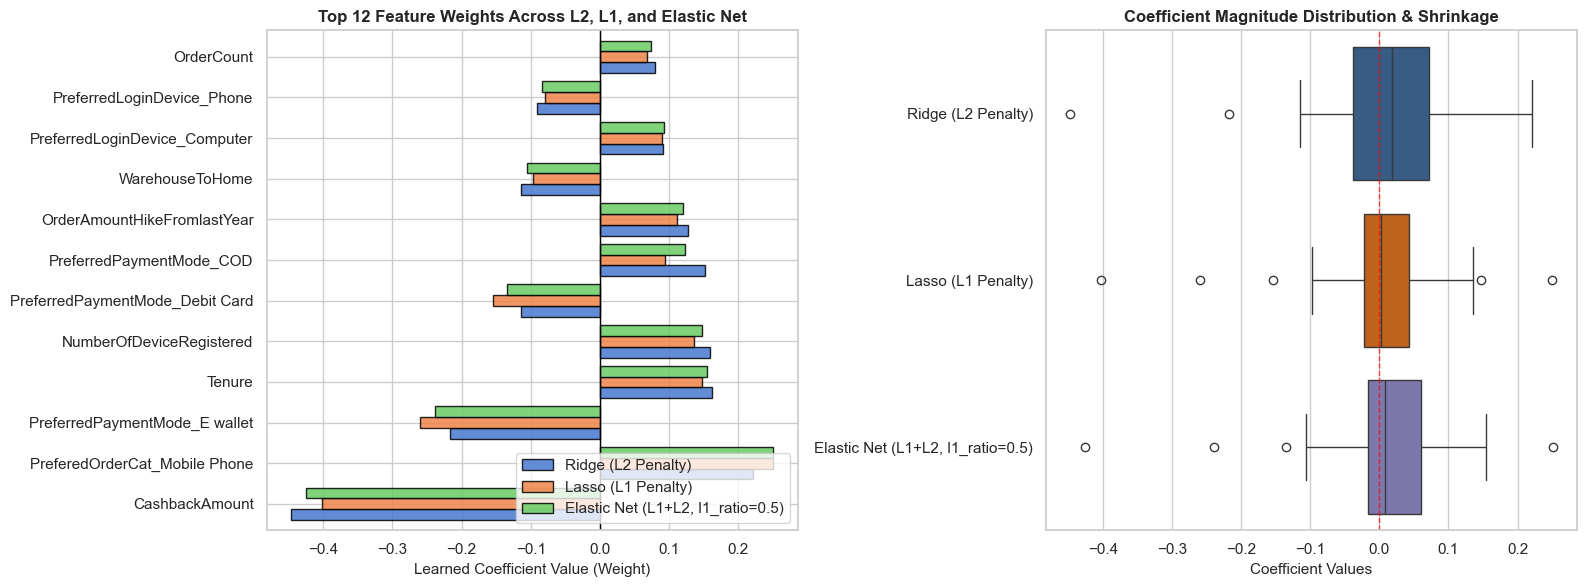

In [11]:
# Part 3.2: Visualizing Coefficient Shrinkage & Sparsity
# Extract transformed feature names
cat_encoder_step = preprocessor.named_transformers_['cat'].named_steps['onehot']
cat_feature_names = list(cat_encoder_step.get_feature_names_out(cat_cols))
all_feature_names = num_cols + cat_feature_names

coef_df = pd.DataFrame(reg_coefs, index=all_feature_names)

fig, (ax_bar, ax_box) = plt.subplots(1, 2, figsize=(16, 6))

# Plot top 12 features by absolute magnitude in Elastic Net
top_features = coef_df['Elastic Net (L1+L2, l1_ratio=0.5)'].abs().nlargest(12).index
coef_df.loc[top_features].plot(kind='barh', ax=ax_bar, width=0.8, edgecolor='black', alpha=0.85)
ax_bar.set_title("Top 12 Feature Weights Across L2, L1, and Elastic Net", fontsize=12, weight='bold')
ax_bar.set_xlabel("Learned Coefficient Value (Weight)", fontsize=11)
ax_bar.axvline(x=0, color='black', lw=1)
ax_bar.legend(loc='lower right')

# Coefficient Distribution & Sparsity Boxplot
sns.boxplot(data=coef_df, orient='h', ax=ax_box, palette=['#2b5c8f', '#d95f02', '#7570b3'])
ax_box.set_title("Coefficient Magnitude Distribution & Shrinkage", fontsize=12, weight='bold')
ax_box.set_xlabel("Coefficient Values", fontsize=11)
ax_box.axvline(x=0, color='red', ls='--', lw=1, alpha=0.7)

plt.tight_layout()
plt.show()

In [12]:
# Part 4.1: Ensemble Learning — Bagging vs. Pasting & OOB Evaluation
# Helper function for estimator backward compatibility across scikit-learn versions
base_dt = DecisionTreeClassifier(random_state=42)

# 1. Bagging Classifier: bootstrap=True, oob_score=True, n_jobs=-1
try:
    bagging_clf = BaggingClassifier(
        estimator=base_dt,
        n_estimators=100,
        bootstrap=True,
        oob_score=True,
        n_jobs=-1,
        random_state=42
    )
except TypeError:
    bagging_clf = BaggingClassifier(
        base_estimator=base_dt,
        n_estimators=100,
        bootstrap=True,
        oob_score=True,
        n_jobs=-1,
        random_state=42
    )

# 2. Pasting Classifier: bootstrap=False, n_jobs=-1
try:
    pasting_clf = BaggingClassifier(
        estimator=base_dt,
        n_estimators=100,
        bootstrap=False,
        n_jobs=-1,
        random_state=42
    )
except TypeError:
    pasting_clf = BaggingClassifier(
        base_estimator=base_dt,
        n_estimators=100,
        bootstrap=False,
        n_jobs=-1,
        random_state=42
    )

# Wrap both in pipelines with preprocessor
bagging_pipe = Pipeline([('preprocessor', preprocessor), ('ensemble', bagging_clf)])
pasting_pipe = Pipeline([('preprocessor', preprocessor), ('ensemble', pasting_clf)])

# Fit Bagging
bagging_pipe.fit(X_train, y_train)
y_pred_bag = bagging_pipe.predict(X_test)
oob_score = bagging_pipe.named_steps['ensemble'].oob_score_

# Fit Pasting
pasting_pipe.fit(X_train, y_train)
y_pred_past = pasting_pipe.predict(X_test)

print("=" * 70)
print("BAGGING (BOOTSTRAP=TRUE) VS. PASTING (BOOTSTRAP=FALSE) BENCHMARK")
print("=" * 70)
ensemble_comp_df = pd.DataFrame([
    {
        'Ensemble Technique': 'Bagging (Bootstrap=True)',
        'OOB Accuracy Score': round(oob_score, 4),
        'Test Accuracy': round(accuracy_score(y_test, y_pred_bag), 4),
        'Test Precision': round(precision_score(y_test, y_pred_bag, zero_division=0), 4),
        'Test Recall': round(recall_score(y_test, y_pred_bag), 4),
        'Test F1-Score': round(f1_score(y_test, y_pred_bag), 4)
    },
    {
        'Ensemble Technique': 'Pasting (Bootstrap=False)',
        'OOB Accuracy Score': 'N/A (No OOB for Pasting)',
        'Test Accuracy': round(accuracy_score(y_test, y_pred_past), 4),
        'Test Precision': round(precision_score(y_test, y_pred_past, zero_division=0), 4),
        'Test Recall': round(recall_score(y_test, y_pred_past), 4),
        'Test F1-Score': round(f1_score(y_test, y_pred_past), 4)
    }
])
display(ensemble_comp_df)
print(f"\n[COMPARISON] OOB Score ({oob_score:.4f}) vs. Test Accuracy ({accuracy_score(y_test, y_pred_bag):.4f})")
print(f"             Absolute Generalization Estimation Error: {abs(oob_score - accuracy_score(y_test, y_pred_bag)):.4f}")

BAGGING (BOOTSTRAP=TRUE) VS. PASTING (BOOTSTRAP=FALSE) BENCHMARK


,Ensemble Technique,OOB Accuracy Score,Test Accuracy,Test Precision,Test Recall,Test F1-Score
0,Bagging (Bootstrap=True),0.8328,0.8330,0.0000,0.0000,0.0000
1,Pasting (Bootstrap=False),N/A (No OOB for Pasting),0.7256,0.2095,0.2353,0.2217



[COMPARISON] OOB Score (0.8328) vs. Test Accuracy (0.8330)
             Absolute Generalization Estimation Error: 0.0002


In [13]:
# Part 4.2: Boosting (AdaBoostClassifier) Implementation & Evaluation
# Base weak learner for AdaBoost: Decision Stump (max_depth=1)
ada_base = DecisionTreeClassifier(max_depth=1, random_state=42)

try:
    adaboost_clf = AdaBoostClassifier(
        estimator=ada_base,
        n_estimators=100,
        learning_rate=1.0,
        random_state=42
    )
except TypeError:
    adaboost_clf = AdaBoostClassifier(
        base_estimator=ada_base,
        n_estimators=100,
        learning_rate=1.0,
        random_state=42
    )

adaboost_pipe = Pipeline([
    ('preprocessor', preprocessor),
    ('adaboost', adaboost_clf)
])

# Train AdaBoost Pipeline
adaboost_pipe.fit(X_train, y_train)

# Evaluate on Test Set
y_pred_ada = adaboost_pipe.predict(X_test)
y_proba_ada = adaboost_pipe.predict_proba(X_test)[:, 1]

print("=" * 65)
print("ADABOOST CLASSIFIER TEST EVALUATION")
print("=" * 65)
print(f"Accuracy:  {accuracy_score(y_test, y_pred_ada):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_ada, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_ada):.4f}")
print(f"F1-Score:  {f1_score(y_test, y_pred_ada):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, y_proba_ada):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_ada, target_names=['Retained (0)', 'Churned (1)']))

ADABOOST CLASSIFIER TEST EVALUATION
Accuracy:  0.8330
Precision: 0.0000
Recall:    0.0000
F1-Score:  0.0000
ROC-AUC:   0.5447

Classification Report:
              precision    recall  f1-score   support

Retained (0)       0.83      1.00      0.91       939
 Churned (1)       0.00      0.00      0.00       187

    accuracy                           0.83      1126
   macro avg       0.42      0.50      0.45      1126
weighted avg       0.70      0.83      0.76      1126



In [14]:
# Part 4.3: Voting Classifiers (Hard vs. Soft Voting)
# Construct three distinct, complementary base classifiers
clf_lr = LogisticRegression(max_iter=2000, random_state=42)
clf_rf = RandomForestClassifier(n_estimators=100, random_state=42)
clf_svc = SVC(probability=True, random_state=42)

# 1. Hard Voting Classifier (Majority Class Vote)
hard_voting_clf = VotingClassifier(
    estimators=[('lr', clf_lr), ('rf', clf_rf), ('svc', clf_svc)],
    voting='hard'
)

# 2. Soft Voting Classifier (Weighted Average Predicted Probabilities)
soft_voting_clf = VotingClassifier(
    estimators=[('lr', clf_lr), ('rf', clf_rf), ('svc', clf_svc)],
    voting='soft'
)

# Wrap inside pipelines
hard_voting_pipe = Pipeline([('preprocessor', preprocessor), ('ensemble', hard_voting_clf)])
soft_voting_pipe = Pipeline([('preprocessor', preprocessor), ('ensemble', soft_voting_clf)])

# Fit both ensembles on training data
hard_voting_pipe.fit(X_train, y_train)
soft_voting_pipe.fit(X_train, y_train)

# Predict on test set
y_pred_hard = hard_voting_pipe.predict(X_test)
y_pred_soft = soft_voting_pipe.predict(X_test)
y_proba_soft = soft_voting_pipe.predict_proba(X_test)[:, 1]

print("=" * 75)
print("VOTING CLASSIFIER COMPARISON: HARD VOTING VS. SOFT VOTING")
print("=" * 75)
voting_comp_df = pd.DataFrame([
    {
        'Voting Strategy': 'Hard Voting (Majority Vote)',
        'Test Acc': round(accuracy_score(y_test, y_pred_hard), 4),
        'Test Precision': round(precision_score(y_test, y_pred_hard, zero_division=0), 4),
        'Test Recall': round(recall_score(y_test, y_pred_hard), 4),
        'Test F1-Score': round(f1_score(y_test, y_pred_hard), 4),
        'Test ROC-AUC': 'N/A (Discrete Predictions)'
    },
    {
        'Voting Strategy': 'Soft Voting (Average Probabilities)',
        'Test Acc': round(accuracy_score(y_test, y_pred_soft), 4),
        'Test Precision': round(precision_score(y_test, y_pred_soft, zero_division=0), 4),
        'Test Recall': round(recall_score(y_test, y_pred_soft), 4),
        'Test F1-Score': round(f1_score(y_test, y_pred_soft), 4),
        'Test ROC-AUC': round(roc_auc_score(y_test, y_proba_soft), 4)
    }
])
display(voting_comp_df)

VOTING CLASSIFIER COMPARISON: HARD VOTING VS. SOFT VOTING


,Voting Strategy,Test Acc,Test Precision,Test Recall,Test F1-Score,Test ROC-AUC
0,Hard Voting (Majority Vote),0.8339,0.0,0.0,0.0,N/A (Discrete Predictions)
1,Soft Voting (Average Probabilities),0.8339,0.0,0.0,0.0,0.5153


CONSOLIDATED BENCHMARK LEADERBOARD (SORTED BY CHURN F1-SCORE)


,Model Pipeline,Accuracy,Precision (Class 1),Recall (Class 1),F1-Score (Class 1),ROC-AUC
0,Pasting (bootstrap=False),0.7256,0.2095,0.2353,0.2217,0.5402
1,Decision Tree (Unconstrained),0.7220,0.2056,0.2353,0.2195,0.5271
2,Decision Tree (max_depth=5),0.8268,0.1000,0.0053,0.0102,0.5124
3,Decision Stump (max_depth=1),0.8339,0.0000,0.0000,0.0000,0.5255
4,Logistic Regression (L2 Ridge),0.8339,0.0000,0.0000,0.0000,0.5273
5,Logistic Regression (L1 Lasso),0.8339,0.0000,0.0000,0.0000,0.5275
6,Logistic Regression (Elastic Net),0.8339,0.0000,0.0000,0.0000,0.5274
7,"Bagging (bootstrap=True, OOB)",0.8330,0.0000,0.0000,0.0000,0.5106
8,AdaBoost (n_est=100),0.8330,0.0000,0.0000,0.0000,0.5447
9,Voting (Hard),0.8339,0.0000,0.0000,0.0000,NaN


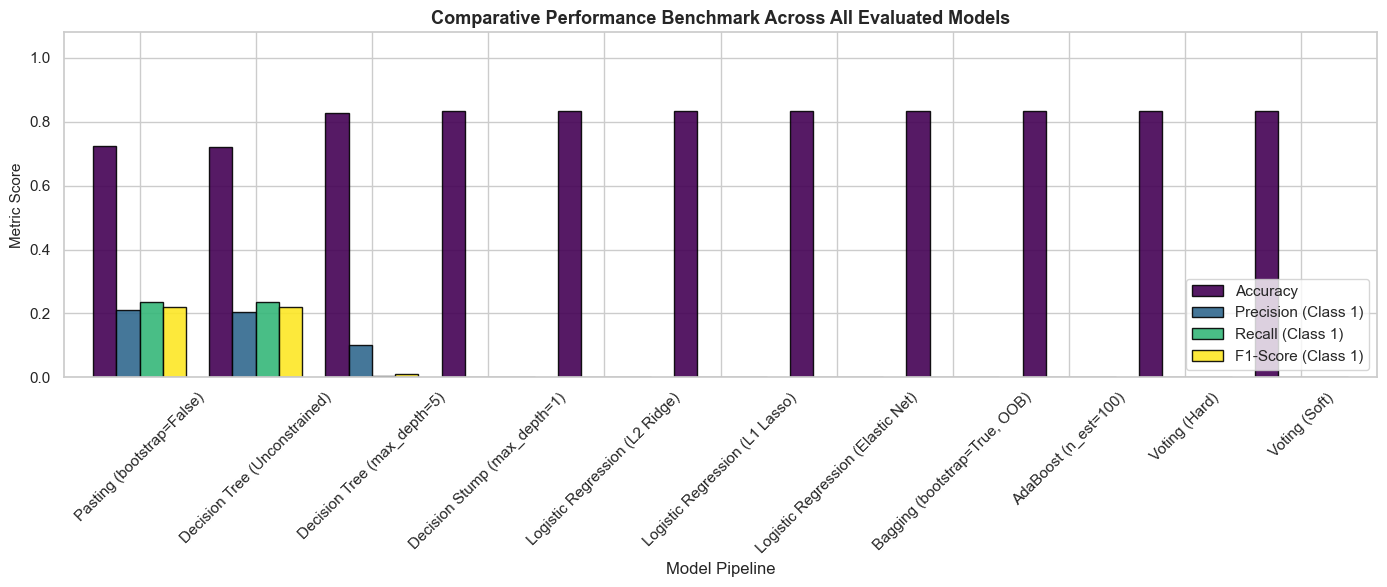

In [15]:
# Part 5: Consolidated Benchmark Table & Performance Visualizations
# Compile complete benchmark across all explored models
all_evaluated_models = {
    'Decision Stump (max_depth=1)': Pipeline([('prep', preprocessor), ('clf', DecisionTreeClassifier(max_depth=1, random_state=42))]),
    'Decision Tree (max_depth=5)': Pipeline([('prep', preprocessor), ('clf', DecisionTreeClassifier(max_depth=5, random_state=42))]),
    'Decision Tree (Unconstrained)': Pipeline([('prep', preprocessor), ('clf', DecisionTreeClassifier(max_depth=None, random_state=42))]),
    'Logistic Regression (L2 Ridge)': Pipeline([('prep', preprocessor), ('clf', LogisticRegression(penalty='l2', solver='saga', max_iter=2000, random_state=42))]),
    'Logistic Regression (L1 Lasso)': Pipeline([('prep', preprocessor), ('clf', LogisticRegression(penalty='l1', solver='saga', max_iter=2000, random_state=42))]),
    'Logistic Regression (Elastic Net)': Pipeline([('prep', preprocessor), ('clf', LogisticRegression(penalty='elasticnet', l1_ratio=0.5, solver='saga', max_iter=2000, random_state=42))]),
    'Bagging (bootstrap=True, OOB)': bagging_pipe,
    'Pasting (bootstrap=False)': pasting_pipe,
    'AdaBoost (n_est=100)': adaboost_pipe,
    'Voting (Hard)': hard_voting_pipe,
    'Voting (Soft)': soft_voting_pipe
}

benchmark_rows = []

for name, model in all_evaluated_models.items():
    # Model may already be fitted or need fit
    try:
        y_test_pred = model.predict(X_test)
    except:
        model.fit(X_train, y_train)
        y_test_pred = model.predict(X_test)
        
    try:
        y_test_proba = model.predict_proba(X_test)[:, 1]
        auc_val = round(roc_auc_score(y_test, y_test_proba), 4)
    except:
        auc_val = np.nan
        
    benchmark_rows.append({
        'Model Pipeline': name,
        'Accuracy': round(accuracy_score(y_test, y_test_pred), 4),
        'Precision (Class 1)': round(precision_score(y_test, y_test_pred, zero_division=0), 4),
        'Recall (Class 1)': round(recall_score(y_test, y_test_pred), 4),
        'F1-Score (Class 1)': round(f1_score(y_test, y_test_pred, zero_division=0), 4),
        'ROC-AUC': auc_val
    })

final_benchmark_df = pd.DataFrame(benchmark_rows).sort_values(by='F1-Score (Class 1)', ascending=False).reset_index(drop=True)

print("=" * 95)
print("CONSOLIDATED BENCHMARK LEADERBOARD (SORTED BY CHURN F1-SCORE)")
print("=" * 95)
display(final_benchmark_df)

# Plot Comparative Bar Chart of Top Models
fig, ax = plt.subplots(figsize=(14, 6))
plot_df = final_benchmark_df.set_index('Model Pipeline')[['Accuracy', 'Precision (Class 1)', 'Recall (Class 1)', 'F1-Score (Class 1)']]
plot_df.plot(kind='bar', ax=ax, width=0.8, edgecolor='black', alpha=0.9, colormap='viridis')
ax.set_title("Comparative Performance Benchmark Across All Evaluated Models", fontsize=13, weight='bold')
ax.set_ylabel("Metric Score", fontsize=11)
ax.set_ylim(0, 1.08)
ax.legend(loc='lower right', frameon=True)
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()